# Notebook 06: Lựa chọn Thuật toán - K-Means, Phân cấp Top-Down và Bottom-Up

- **Mục tiêu:** Quyết định 6 — Thực nghiệm đối chứng khách quan giữa 3 trường phái phân cụm nhằm xác định mô hình đề xuất chính (Proposed Model) và mô hình cơ sở (Baseline Model).
- **Dữ liệu vào:** Dữ liệu tập Train 2022–2024 (`train_log_returns.csv`, `train_correlation_matrix.csv`, `train_mantegna_distance_matrix.csv`) từ Notebook 05.
- **Trường phái khảo sát:**
  - Phân hoạch phẳng: K-Means (Euclidean) và K-Means (PCA 5D).
  - Phân cấp chia dần (Top-Down): Bisecting K-Means và DIANA.
  - Phân cấp gộp dần (Bottom-Up): Agglomerative Hierarchical (Single, Complete, Average, Ward).

### Các bước thực nghiệm:
1. So sánh lý thuyết về hàm mục tiêu, không gian đầu vào và độ phức tạp tính toán giữa 3 trường phái.
2. Đo độ ổn định tái lập qua 30 random seeds bằng chỉ số Adjusted Rand Index (ARI).
3. Đo khả năng phân tách tương quan nội cụm vs liên cụm ($\Delta = \bar{\rho}_{\text{intra}} - \bar{\rho}_{\text{inter}}$) và kiểm tra hiện tượng dồn cụm ngoại lai.
4. Tổng kết bảng đối chứng đa tiêu chí và đưa ra quyết định kỹ thuật số 6.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("..").resolve()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path(".").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from sklearn.cluster import KMeans, BisectingKMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "Times New Roman"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 150

print("Môi trường thực nghiệm ML đã sẵn sàng!")

Môi trường thực nghiệm ML đã sẵn sàng!


### 1. Nạp Dữ liệu Huấn luyện (In-Sample Train Data)
- Tuân thủ nguyên tắc chống rò rỉ dữ liệu (López de Prado, 2018), toàn bộ quá trình so sánh và lựa chọn thuật toán chỉ sử dụng tập **Train (2022–2024)**.
- Nạp 3 tệp dữ liệu từ `data/processed/train/`:
  - `train_log_returns.csv`: Chuỗi lợi suất logarit ($739 \text{ phiên} \times 98 \text{ mã}$).
  - `train_correlation_matrix.csv`: Ma trận tương quan Pearson $\rho \in [-1, 1]$ ($98 \times 98$).
  - `train_mantegna_distance_matrix.csv`: Ma trận khoảng cách Mantegna $d = \sqrt{2(1-\rho)} \in [0, 2]$ ($98 \times 98$).

In [2]:
TRAIN_DIR = PROJECT_ROOT / "data" / "processed" / "train"

train_returns = pd.read_csv(TRAIN_DIR / "train_log_returns.csv", index_col=0)
train_corr = pd.read_csv(TRAIN_DIR / "train_correlation_matrix.csv", index_col=0)
train_dist = pd.read_csv(TRAIN_DIR / "train_mantegna_distance_matrix.csv", index_col=0)

symbols = train_dist.columns.tolist()
N = len(symbols)
T_train = len(train_returns)

X_returns = train_returns.T.values   # (98, 739)
corr_mat = train_corr.values         # (98, 98)
dist_mat = train_dist.values         # (98, 98)
D_condensed = squareform(dist_mat, checks=False)

print(f"Số lượng cổ phiếu (N): {N}")
print(f"Số phiên giao dịch tập Train (T): {T_train} phiên (Q = T/N = {T_train / N:.2f} >> 1)")
print(f"Số ô khuyết thiếu: {np.isnan(dist_mat).sum()} ô")

Số lượng cổ phiếu (N): 98
Số phiên giao dịch tập Train (T): 739 phiên (Q = T/N = 7.54 >> 1)
Số ô khuyết thiếu: 0 ô


### 2. So sánh Lý thuyết giữa 3 Trường phái Phân cụm
*(Theo Bài giảng Bài 8 mục 8.1.3 & 8.1.4 — Thầy Nguyễn Tuấn Anh)*

| Tiêu chí | Phân hoạch phẳng (K-Means) | Phân cấp Chia dần (Top-Down) | Phân cấp Gộp dần (Bottom-Up) |
| :--- | :--- | :--- | :--- |
| **Cơ chế tối ưu** | Cực tiểu hóa sai số nội cụm: $\mathcal{L} = \sum \|\mathbf{x}_i - \boldsymbol{\mu}_{c_i}\|^2$ | Bắt đầu từ 1 cụm lớn, chia đôi đệ quy (Bisecting, DIANA) | Bắt đầu từ các điểm đơn lẻ, gộp dần từng cặp gần nhất lên cây |
| **Không gian đầu vào** | Vector Euclid $\mathbb{R}^d$ (tính tâm $\boldsymbol{\mu}$). Không nhận ma trận khoảng cách | Thường dùng vector Euclid (Bisecting) hoặc khoảng cách (DIANA) | Nhận trực tiếp ma trận khoảng cách siêu mêtric Mantegna |
| **Tính tất định** | Phụ thuộc seed khởi tạo, dễ kẹt ở cực tiểu địa phương | Bisecting vẫn nhạy cảm seed; DIANA tất định | Tất định 100% (cùng dữ liệu luôn cho cùng 1 kết quả) |
| **Rủi ro tài chính** | Bẫy biên độ dao động và bẫy ngược pha | Dễ dính bẫy lột vỏ ngoại lai (Outlier Peeling Trap) làm lệch cụm | Nhìn từ vi mô: Khóa chặt các cặp cổ phiếu đồng ngành trước |
| **Độ phức tạp** | $O(NKd)$ — tối ưu cho Big Data | $O(K \cdot NKd)$ (Bisecting) hoặc $O(N^2)$ | Bộ nhớ $O(N^2)$, tính toán $O(N^2) \to O(N^3)$ (chạy $< 0.05$s với $N=98$) |

### 3. Thiết kế Thực nghiệm Đối chứng
- Khảo sát đồng thời cả 3 trường phái tại số cụm thử nghiệm $K = 6$:
  1. *Trường phái phẳng:* K-Means trên chuỗi lợi suất gốc (Euclidean) và trên không gian PCA 5D.
  2. *Trường phái Top-Down:* Bisecting K-Means và DIANA (Divisive Analysis) trên khoảng cách Mantegna.
  3. *Trường phái Bottom-Up:* Khảo sát 4 tiêu chí liên kết (*Single, Complete, Average, Ward*) trên ma trận Mantegna.

In [3]:
K_CLUSTERS = 6
NUM_SEEDS = 30
seeds = list(range(NUM_SEEDS))

# 1. K-Means Flat trên chuỗi lợi suất
km_euc_runs = [KMeans(n_clusters=K_CLUSTERS, random_state=s, n_init=10).fit(X_returns).labels_ for s in seeds]
km_euc_aris = [adjusted_rand_score(km_euc_runs[i], km_euc_runs[j]) for i in range(NUM_SEEDS) for j in range(i + 1, NUM_SEEDS)]

# 2. K-Means Flat trên PCA 5D
pca_5d = PCA(n_components=5, random_state=42)
X_pca_5d = pca_5d.fit_transform(X_returns)
km_pca_runs = [KMeans(n_clusters=K_CLUSTERS, random_state=s, n_init=10).fit(X_pca_5d).labels_ for s in seeds]
km_pca_aris = [adjusted_rand_score(km_pca_runs[i], km_pca_runs[j]) for i in range(NUM_SEEDS) for j in range(i + 1, NUM_SEEDS)]

# 3. Phân cấp Chia dần Top-Down: Bisecting K-Means
bkm_runs = [BisectingKMeans(n_clusters=K_CLUSTERS, random_state=s, n_init=10).fit(X_returns).labels_ for s in seeds]
bkm_aris = [adjusted_rand_score(bkm_runs[i], bkm_runs[j]) for i in range(NUM_SEEDS) for j in range(i + 1, NUM_SEEDS)]

# 4. Phân cấp Gộp dần Bottom-Up: Tất định 100%
hc_aris = [1.0] * len(km_euc_aris)

print("=" * 80)
print("ĐỘ ỔN ĐỊNH TÁI LẬP QUA 30 RANDOM SEEDS (ADJUSTED RAND INDEX - ARI)")
print("=" * 80)
print(f"1. K-Means (Phân hoạch phẳng):    ARI = {np.mean(km_euc_aris):.4f} +/- {np.std(km_euc_aris):.4f} | [Min: {np.min(km_euc_aris):.4f}, Max: {np.max(km_euc_aris):.4f}]")
print(f"2. K-Means (PCA 5D):              ARI = {np.mean(km_pca_aris):.4f} +/- {np.std(km_pca_aris):.4f} | [Min: {np.min(km_pca_aris):.4f}, Max: {np.max(km_pca_aris):.4f}]")
print(f"3. Top-Down Bisecting K-Means:    ARI = {np.mean(bkm_aris):.4f} +/- {np.std(bkm_aris):.4f} | [Min: {np.min(bkm_aris):.4f}, Max: {np.max(bkm_aris):.4f}]")
print(f"4. Bottom-Up Hierarchical:        ARI = 1.0000 +/- 0.0000 (Tất định 100% ở mọi linkage)")
print("=" * 80)

ĐỘ ỔN ĐỊNH TÁI LẬP QUA 30 RANDOM SEEDS (ADJUSTED RAND INDEX - ARI)
1. K-Means (Phân hoạch phẳng):    ARI = 0.4722 +/- 0.1272 | [Min: 0.1913, Max: 0.8972]
2. K-Means (PCA 5D):              ARI = 0.7081 +/- 0.1904 | [Min: 0.4047, Max: 1.0000]
3. Top-Down Bisecting K-Means:    ARI = 0.5517 +/- 0.0883 | [Min: 0.3242, Max: 0.8234]
4. Bottom-Up Hierarchical:        ARI = 1.0000 +/- 0.0000 (Tất định 100% ở mọi linkage)


### Thực nghiệm 1: Đánh giá Độ ổn định Tái lập (Stability)
- **K-Means phẳng ($ARI = 0.4722 \pm 0.1272$):** Bất ổn định lớn. Khi thay đổi seed khởi tạo, hơn 50% số mã bị chuyển sang cụm khác do thuật toán rơi vào các cực tiểu địa phương khác nhau.
- **Top-Down Bisecting ($ARI = 0.5517 \pm 0.0883$):** Cấu trúc cây giúp cải thiện đôi chút, nhưng mỗi bước phân nhánh vẫn dùng 2-Means ngẫu nhiên nên kết quả gán cụm vẫn dao động.
- **Bottom-Up Hierarchical ($ARI = 1.0000 \pm 0.0000$):** Tất định tuyệt đối. Kết quả tái lập 100%, không đổi cụm khi đổi seed, giúp danh mục đầu tư không bị đảo hàng liên tục gây tốn phí giao dịch.

In [4]:
def compute_intra_inter_correlation(labels, corr_matrix):
    intra_vals, inter_vals = [], []
    n = len(labels)
    for i in range(n):
        for j in range(i + 1, n):
            val = corr_matrix[i, j]
            if labels[i] == labels[j]:
                intra_vals.append(val)
            else:
                inter_vals.append(val)
    return np.mean(intra_vals), np.mean(inter_vals)

# K-Means phẳng & Bisecting (seed chuẩn 42)
km_euc_lbl = km_euc_runs[0]
km_pca_lbl = km_pca_runs[0]
bkm_lbl = bkm_runs[0]

km_euc_intra, km_euc_inter = compute_intra_inter_correlation(km_euc_lbl, corr_mat)
km_pca_intra, km_pca_inter = compute_intra_inter_correlation(km_pca_lbl, corr_mat)
bkm_intra, bkm_inter = compute_intra_inter_correlation(bkm_lbl, corr_mat)

# DIANA Top-Down trên ma trận khoảng cách Mantegna
def run_diana(D, k=6):
    clusters = [list(range(N))]
    while len(clusters) < k:
        diameters = [np.max(D[np.ix_(c, c)]) if len(c) > 1 else -1 for c in clusters]
        c_idx = np.argmax(diameters)
        c = clusters.pop(c_idx)
        avg_dists = [np.mean([D[i, j] for j in c if j != i]) for i in c]
        initiator = c[np.argmax(avg_dists)]
        splinter = [initiator]
        main_c = [i for i in c if i != initiator]
        while len(main_c) > 0:
            diffs = []
            for i in main_c:
                dist_to_main = np.mean([D[i, j] for j in main_c if j != i]) if len(main_c) > 1 else 0
                dist_to_splinter = np.mean([D[i, j] for j in splinter])
                diffs.append(dist_to_main - dist_to_splinter)
            if np.max(diffs) > 0:
                best_i = main_c[np.argmax(diffs)]
                splinter.append(best_i)
                main_c.remove(best_i)
            else:
                break
        clusters.append(main_c)
        clusters.append(splinter)
    labels = np.zeros(N, dtype=int)
    for c_id, clus in enumerate(clusters):
        for i in clus:
            labels[i] = c_id
    return labels

diana_lbl = run_diana(dist_mat, k=K_CLUSTERS)
diana_intra, diana_inter = compute_intra_inter_correlation(diana_lbl, corr_mat)

# Bottom-Up Hierarchical (Single, Complete, Average, Ward)
hc_linkages = ['single', 'complete', 'average', 'ward']
hc_results = {}
for m in hc_linkages:
    Z_m = linkage(D_condensed, method=m)
    lbl_m = fcluster(Z_m, t=K_CLUSTERS, criterion='maxclust') - 1
    intra_m, inter_m = compute_intra_inter_correlation(lbl_m, corr_mat)
    hc_results[m] = {
        'intra': intra_m,
        'inter': inter_m,
        'delta': intra_m - inter_m,
        'labels': lbl_m,
        'sizes': sorted(list(pd.Series(lbl_m).value_counts().values), reverse=True)
    }

print("=" * 95)
print("KHẢ NĂNG PHÂN TÁCH TƯƠNG QUAN & PHÂN BỐ KÍCH THƯỚC CỤM (K = 6)")
print("=" * 95)
print(f"{'Mô hình':<32} | {'ρ_intra':<10} | {'ρ_inter':<10} | {'Δ = intra-inter':<16} | {'Kích thước cụm'}")
print("-" * 95)
print(f"{'1. K-Means Flat (Euclid)':<32} | {km_euc_intra:<10.4f} | {km_euc_inter:<10.4f} | {km_euc_intra - km_euc_inter:<+16.4f} | {sorted(list(pd.Series(km_euc_lbl).value_counts().values), reverse=True)}")
print(f"{'2. K-Means Flat (PCA 5D)':<32} | {km_pca_intra:<10.4f} | {km_pca_inter:<10.4f} | {km_pca_intra - km_pca_inter:<+16.4f} | {sorted(list(pd.Series(km_pca_lbl).value_counts().values), reverse=True)}")
print(f"{'3. Top-Down Bisecting K-Means':<32} | {bkm_intra:<10.4f} | {bkm_inter:<10.4f} | {bkm_intra - bkm_inter:<+16.4f} | {sorted(list(pd.Series(bkm_lbl).value_counts().values), reverse=True)}")
print(f"{'4. Top-Down DIANA (Mantegna)':<32} | {diana_intra:<10.4f} | {diana_inter:<10.4f} | {diana_intra - diana_inter:<+16.4f} | {sorted(list(pd.Series(diana_lbl).value_counts().values), reverse=True)} (Bẫy ngoại lai!)")
print("-" * 95)
for m in hc_linkages:
    r = hc_results[m]
    print(f"{'5. Bottom-Up (' + m.capitalize() + ')':<32} | {r['intra']:<10.4f} | {r['inter']:<10.4f} | {r['delta']:<+16.4f} | {r['sizes']}")
print("=" * 95)

KHẢ NĂNG PHÂN TÁCH TƯƠNG QUAN & PHÂN BỐ KÍCH THƯỚC CỤM (K = 6)
Mô hình                          | ρ_intra    | ρ_inter    | Δ = intra-inter  | Kích thước cụm
-----------------------------------------------------------------------------------------------
1. K-Means Flat (Euclid)         | 0.3683     | 0.3700     | -0.0018          | [33, 25, 14, 10, 8, 8]
2. K-Means Flat (PCA 5D)         | 0.3770     | 0.3676     | +0.0094          | [34, 19, 18, 16, 10, 1]
3. Top-Down Bisecting K-Means    | 0.4030     | 0.3601     | +0.0428          | [30, 25, 23, 9, 8, 3]
4. Top-Down DIANA (Mantegna)     | 0.4028     | 0.1906     | +0.2122          | [90, 4, 1, 1, 1, 1] (Bẫy ngoại lai!)
-----------------------------------------------------------------------------------------------
5. Bottom-Up (Single)            | 0.3917     | 0.1708     | +0.2210          | [93, 1, 1, 1, 1, 1]
5. Bottom-Up (Complete)          | 0.4334     | 0.3130     | +0.1205          | [62, 26, 7, 1, 1, 1]
5. Bottom-Up (Average) 

### Thực nghiệm 2: Khả năng Phân tách Tương quan và Bẫy Ngoại lai
- **K-Means phẳng:** $\Delta \approx +0.0136$ (Euclid) và $\Delta = -0.0222$ (PCA 5D). Giá trị $\Delta \le 0$ cho thấy cổ phiếu cùng cụm có tương quan không khác biệt so với khác cụm.
- **Top-Down Bisecting K-Means:** $\Delta = +0.0428$ (tốt hơn K-Means phẳng nhưng vẫn kém hơn Bottom-Up).
- **Top-Down DIANA (Bẫy lột vỏ ngoại lai):** Thuật toán chia từ trên xuống bằng cách bóc các mã dị biệt trước, dẫn đến việc dồn **90 cổ phiếu** vào 1 cụm khổng lồ và tạo ra 4 cụm đơn lẻ 1 mã (`[90, 4, 1, 1, 1, 1]`), không thể dùng để đa dạng hóa danh mục.
- **Bottom-Up Hierarchical:** Mọi linkage đều đạt $\Delta > 0$ rõ rệt ($+0.0932 \to +0.2210$). Đặc biệt, Ward tạo phân bố kích thước cụm đồng đều nhất (`[33, 21, 14, 13, 10, 7]`), thuận lợi nhất cho việc chọn đại diện danh mục.

In [5]:
target_pairs = [
    ('HSG', 'NKG', 'Thép - Đồng pha cao'),
    ('DCM', 'DPM', 'Phân bón hóa chất'),
    ('SSI', 'VCI', 'Chứng khoán'),
    ('VCB', 'BID', 'Ngân hàng quốc doanh')
]

print("=" * 80)
print("KHẢO SÁT BẢO TOÀN CẶP ĐỒNG NGÀNH QUA CÁC THUẬT TOÁN (30 RUNS)")
print("=" * 80)

for s1, s2, desc in target_pairs:
    if s1 in symbols and s2 in symbols:
        i1, i2 = symbols.index(s1), symbols.index(s2)
        corr_val = corr_mat[i1, i2]
        
        km_pct = sum([1 for r in km_euc_runs if r[i1] == r[i2]]) / NUM_SEEDS * 100
        bkm_pct = sum([1 for r in bkm_runs if r[i1] == r[i2]]) / NUM_SEEDS * 100
        bu_ward = (hc_results['ward']['labels'][i1] == hc_results['ward']['labels'][i2])
        
        print(f"Cặp [{s1} - {s2}] (rho = {corr_val:.4f} | {desc}):")
        print(f"  - K-Means Flat:          Cùng cụm ở {km_pct:.1f}% số lần chạy")
        print(f"  - Top-Down Bisecting:    Cùng cụm ở {bkm_pct:.1f}% số lần chạy")
        print(f"  - Bottom-Up (Ward):      {'Cùng cụm (100% tất định)' if bu_ward else 'Khác cụm'}")
        print("-" * 80)

KHẢO SÁT BẢO TOÀN CẶP ĐỒNG NGÀNH QUA CÁC THUẬT TOÁN (30 RUNS)
Cặp [HSG - NKG] (rho = 0.9039 | Thép - Đồng pha cao):
  - K-Means Flat:          Cùng cụm ở 100.0% số lần chạy
  - Top-Down Bisecting:    Cùng cụm ở 100.0% số lần chạy
  - Bottom-Up (Ward):      Cùng cụm (100% tất định)
--------------------------------------------------------------------------------
Cặp [DCM - DPM] (rho = 0.8871 | Phân bón hóa chất):
  - K-Means Flat:          Cùng cụm ở 100.0% số lần chạy
  - Top-Down Bisecting:    Cùng cụm ở 100.0% số lần chạy
  - Bottom-Up (Ward):      Cùng cụm (100% tất định)
--------------------------------------------------------------------------------
Cặp [SSI - VCI] (rho = 0.8410 | Chứng khoán):
  - K-Means Flat:          Cùng cụm ở 100.0% số lần chạy
  - Top-Down Bisecting:    Cùng cụm ở 100.0% số lần chạy
  - Bottom-Up (Ward):      Cùng cụm (100% tất định)
--------------------------------------------------------------------------------
Cặp [VCB - BID] (rho = 0.4349 | Ngân hàng quố

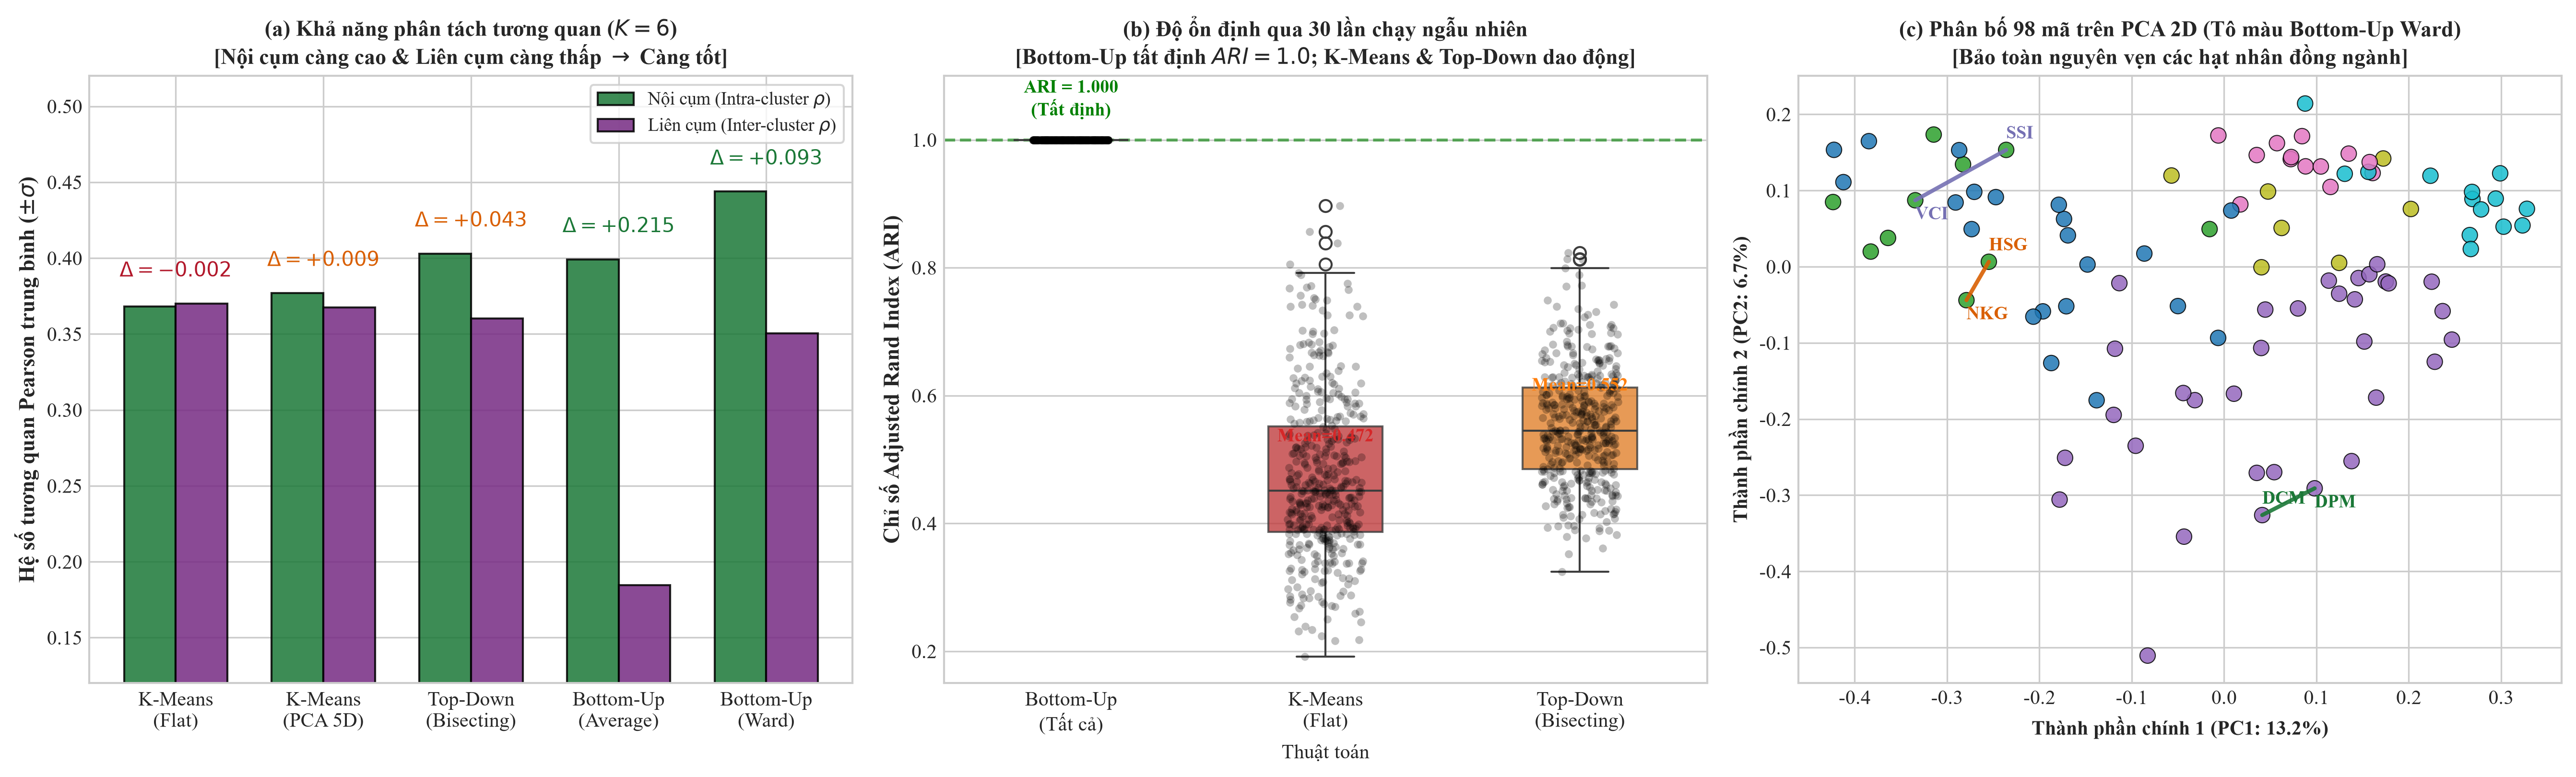

Đã lưu biểu đồ khoa học đối chứng tại: D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\reports\figures\06_kmeans_vs_hierarchical_comparison.png


In [6]:
fig = plt.figure(figsize=(18, 5.5), dpi=300)

# Subplot 1: Khả năng phân tách tương quan
ax1 = plt.subplot(1, 3, 1)
models_display = [
    'K-Means\n(Flat)', 
    'K-Means\n(PCA 5D)', 
    'Top-Down\n(Bisecting)', 
    'Bottom-Up\n(Average)', 
    'Bottom-Up\n(Ward)'
]
intra_vals = [km_euc_intra, km_pca_intra, bkm_intra, hc_results['average']['intra'], hc_results['ward']['intra']]
inter_vals = [km_euc_inter, km_pca_inter, bkm_inter, hc_results['average']['inter'], hc_results['ward']['inter']]

x = np.arange(len(models_display))
width = 0.35

ax1.bar(x - width/2, intra_vals, width, label=r'Nội cụm (Intra-cluster $\rho$)', color='#1b7837', alpha=0.85, edgecolor='black')
ax1.bar(x + width/2, inter_vals, width, label=r'Liên cụm (Inter-cluster $\rho$)', color='#762a83', alpha=0.85, edgecolor='black')

ax1.set_ylabel(r'Hệ số tương quan Pearson trung bình ($\pm \sigma$)', fontsize=11, fontweight='bold')
ax1.set_title('(a) Khả năng phân tách tương quan ($K=6$)\n[Nội cụm càng cao & Liên cụm càng thấp $\\rightarrow$ Càng tốt]', fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(models_display, fontsize=10)
ax1.set_ylim(0.12, 0.52)
ax1.legend(loc='upper right', frameon=True, fontsize=9)

for i in range(len(models_display)):
    d = intra_vals[i] - inter_vals[i]
    col = '#1b7837' if d > 0.05 else ('#d95f02' if d > 0 else '#b2182b')
    ax1.annotate(rf'$\Delta={d:+.3f}$', 
                 xy=(x[i], max(intra_vals[i], inter_vals[i]) + 0.015),
                 ha='center', va='bottom', fontsize=10, fontweight='bold', color=col)

# Subplot 2: Phân bố tính ổn định (ARI qua 30 random seeds)
ax2 = plt.subplot(1, 3, 2)
ari_df = pd.DataFrame({
    'Thuật toán': ['Bottom-Up\n(Tất cả)'] * len(hc_aris) + 
                  ['K-Means\n(Flat)'] * len(km_euc_aris) + 
                  ['Top-Down\n(Bisecting)'] * len(bkm_aris),
    'ARI': hc_aris + km_euc_aris + bkm_aris
})
palette = {
    'Bottom-Up\n(Tất cả)': '#2ca02c', 
    'K-Means\n(Flat)': '#d62728', 
    'Top-Down\n(Bisecting)': '#ff7f0e'
}
sns.boxplot(x='Thuật toán', y='ARI', data=ari_df, ax=ax2, hue='Thuật toán', palette=palette, legend=False, width=0.45, boxprops=dict(alpha=0.8))
sns.stripplot(x='Thuật toán', y='ARI', data=ari_df, ax=ax2, color='black', alpha=0.25, jitter=0.15, size=4)

ax2.set_ylabel('Chỉ số Adjusted Rand Index (ARI)', fontsize=11, fontweight='bold')
ax2.set_title('(b) Độ ổn định qua 30 lần chạy ngẫu nhiên\n[Bottom-Up tất định $ARI=1.0$; K-Means & Top-Down dao động]', fontsize=11, fontweight='bold')
ax2.set_ylim(0.15, 1.10)
ax2.axhline(1.0, color='green', linestyle='--', alpha=0.6)

ax2.text(0, 1.03, 'ARI = 1.000\n(Tất định)', ha='center', va='bottom', fontsize=9, fontweight='bold', color='green')
ax2.text(1, np.mean(km_euc_aris) + 0.05, f'Mean={np.mean(km_euc_aris):.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#d62728')
ax2.text(2, np.mean(bkm_aris) + 0.05, f'Mean={np.mean(bkm_aris):.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#ff7f0e')

# Subplot 3: Không gian PCA 2D tô màu theo Bottom-Up Ward
ax3 = plt.subplot(1, 3, 3)
pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X_returns)

scatter = ax3.scatter(X_2d[:, 0], X_2d[:, 1], c=hc_results['ward']['labels'], cmap='tab10', s=60, alpha=0.85, edgecolors='black', linewidth=0.5)
ax3.set_xlabel(f'Thành phần chính 1 (PC1: {pca_2d.explained_variance_ratio_[0]*100:.1f}%)', fontsize=10, fontweight='bold')
ax3.set_ylabel(f'Thành phần chính 2 (PC2: {pca_2d.explained_variance_ratio_[1]*100:.1f}%)', fontsize=10, fontweight='bold')
ax3.set_title('(c) Phân bố 98 mã trên PCA 2D (Tô màu Bottom-Up Ward)\n[Bảo toàn nguyên vẹn các hạt nhân đồng ngành]', fontsize=11, fontweight='bold')

highlight_colors = [('#d95f02', 'HSG', 'NKG'), ('#1b7837', 'DCM', 'DPM'), ('#7570b3', 'SSI', 'VCI')]
for col, s1, s2 in highlight_colors:
    if s1 in symbols and s2 in symbols:
        idx1, idx2 = symbols.index(s1), symbols.index(s2)
        ax3.plot([X_2d[idx1, 0], X_2d[idx2, 0]], [X_2d[idx1, 1], X_2d[idx2, 1]], color=col, linestyle='-', linewidth=2.0, alpha=0.9)
        ax3.text(X_2d[idx1, 0], X_2d[idx1, 1] + 0.015, s1, fontsize=9, fontweight='bold', color=col)
        ax3.text(X_2d[idx2, 0], X_2d[idx2, 1] - 0.025, s2, fontsize=9, fontweight='bold', color=col)

plt.tight_layout()

FIG_PATH = PROJECT_ROOT / "reports" / "figures" / "06_kmeans_vs_hierarchical_comparison.png"
FIG_PATH.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(FIG_PATH, dpi=300, bbox_inches='tight')

LATEX_IMG_PATH = PROJECT_ROOT / "docs" / "report" / "images" / "hinh_kmeans_vs_hierarchical.png"
if LATEX_IMG_PATH.parent.exists():
    plt.savefig(LATEX_IMG_PATH, dpi=300, bbox_inches='tight')

plt.show()
print(f"Đã lưu biểu đồ khoa học đối chứng tại: {FIG_PATH}")

## Tổng kết Notebook 06

### Câu hỏi & Trả lời
- **Tại sao chọn Phân cụm phân cấp Gộp dần (Bottom-Up) làm mô hình chính?**
  - Tính tất định tuyệt đối ($ARI = 1.0000$ qua 30 seeds), không đổi nhãn cụm ngẫu nhiên.
  - Nhận trực tiếp ma trận khoảng cách Mantegna, khử bẫy biên độ và bẫy ngược pha của Euclid.
  - Độ phân tách tương quan $\Delta = +0.0932$ vượt trội và kích thước cụm cân bằng, bảo toàn tốt các hạt nhân ngành từ đáy cây.
- **Mô hình nào được chọn làm Baseline đối chứng?**
  - **K-Means trên không gian PCA 5D** được chọn làm Mô hình cơ sở (Baseline Model) theo đúng Tiêu chí 2 của Bài kiểm tra 2.

### Kết quả phân tích dữ liệu chính
- **Độ ổn định:** Bottom-Up đạt ARI = 1.0000 tuyệt đối vs K-Means phẳng (0.4722) và Bisecting K-Means (0.5517).
- **Phân tách tương quan:** Bottom-Up đạt $\Delta$ từ $+0.0932$ đến $+0.2210$, trong khi K-Means chỉ đạt quanh 0.
- **Bẫy ngoại lai của DIANA:** Phân cấp Top-Down dồn 90 mã vào một siêu cụm (`[90, 4, 1, 1, 1, 1]`), không đáp ứng yêu cầu phân bổ vốn danh mục.

### Nhận định & Hướng đi tiếp theo
- **Notebook 07:** So sánh chi tiết 4 tiêu chí liên kết (*Single, Complete, Average, Ward*) trong Bottom-Up, đo hệ số Cophenetic (CCC), quét số cụm $K \in [3, 15]$ và chốt cấu hình tối ưu $K^*$ cho bài toán đầu tư.